In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="DESRES_FOLDING", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    try:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
    except:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    try:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
    except:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    try:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    except:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(protein, model_name, native_contacts_dir, ensemble_dir="DESRES_FOLDING", nbins=30, unfolded_cutoff=0.1, wopt=None, w0=None, T=298.0):
    k = 0.008314
    kT = k * T

    trajs = find_xtc_filenames(f"../../{ensemble_dir}/{protein}/")
    # get correct traj order
    trajs = np.array(sorted(trajs))

    # Load Q data
    for i, traj in enumerate(trajs):
        try:
            frames = np.loadtxt(f"../../{ensemble_dir}/{protein}/rewM10_dGprior/okframes_traj{traj}.txt").astype(int)
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q_{traj}.txt")[frames]
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
        except: # for models where no filtering was needed
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q_{traj}.txt")
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
    if wopt is None:
        try:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_wopt.npy")
        except:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/wopt.npy")
        wopt = wopt / np.sum(wopt)
    if w0 is None:
        w0 = np.ones(wopt.shape[0])/wopt.shape[0] # uniform MD prior
        #w0 = np.loadtxt(f"../../{ensemble_dir}/{protein}/w_prior_dG_BME.txt").astype(float)
        #w0 = w0 / np.sum(w0)

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q_all, weights=w0)
    centers_post, fel_post = compute_FEL(Q_all, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q_all < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q_all > native_cutoff)[0]

    dG_prior = -kT * np.log(np.sum(w0[folded]) / np.sum(w0[unfolded])) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q_all > native_cutoff2)[0]
    unfolded = np.where(Q_all < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(np.sum(w0[folded]) / np.sum(w0[unfolded])) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

def find_second_elbow(x, y):
    # First elbow
    idx1, x1, y1 = find_elbow(x, y)

    # Slice data from first elbow to end
    if idx1 >= len(x) - 2:
        raise ValueError("Not enough points after the first elbow to find a second elbow.")

    x_sub = x[idx1:]
    y_sub = y[idx1:]

    # Find elbow in the remaining segment
    idx2_sub, x2, y2 = find_elbow(x_sub, y_sub)

    # Convert back to original index
    idx2 = idx1 + idx2_sub

    return idx2, x2, y2


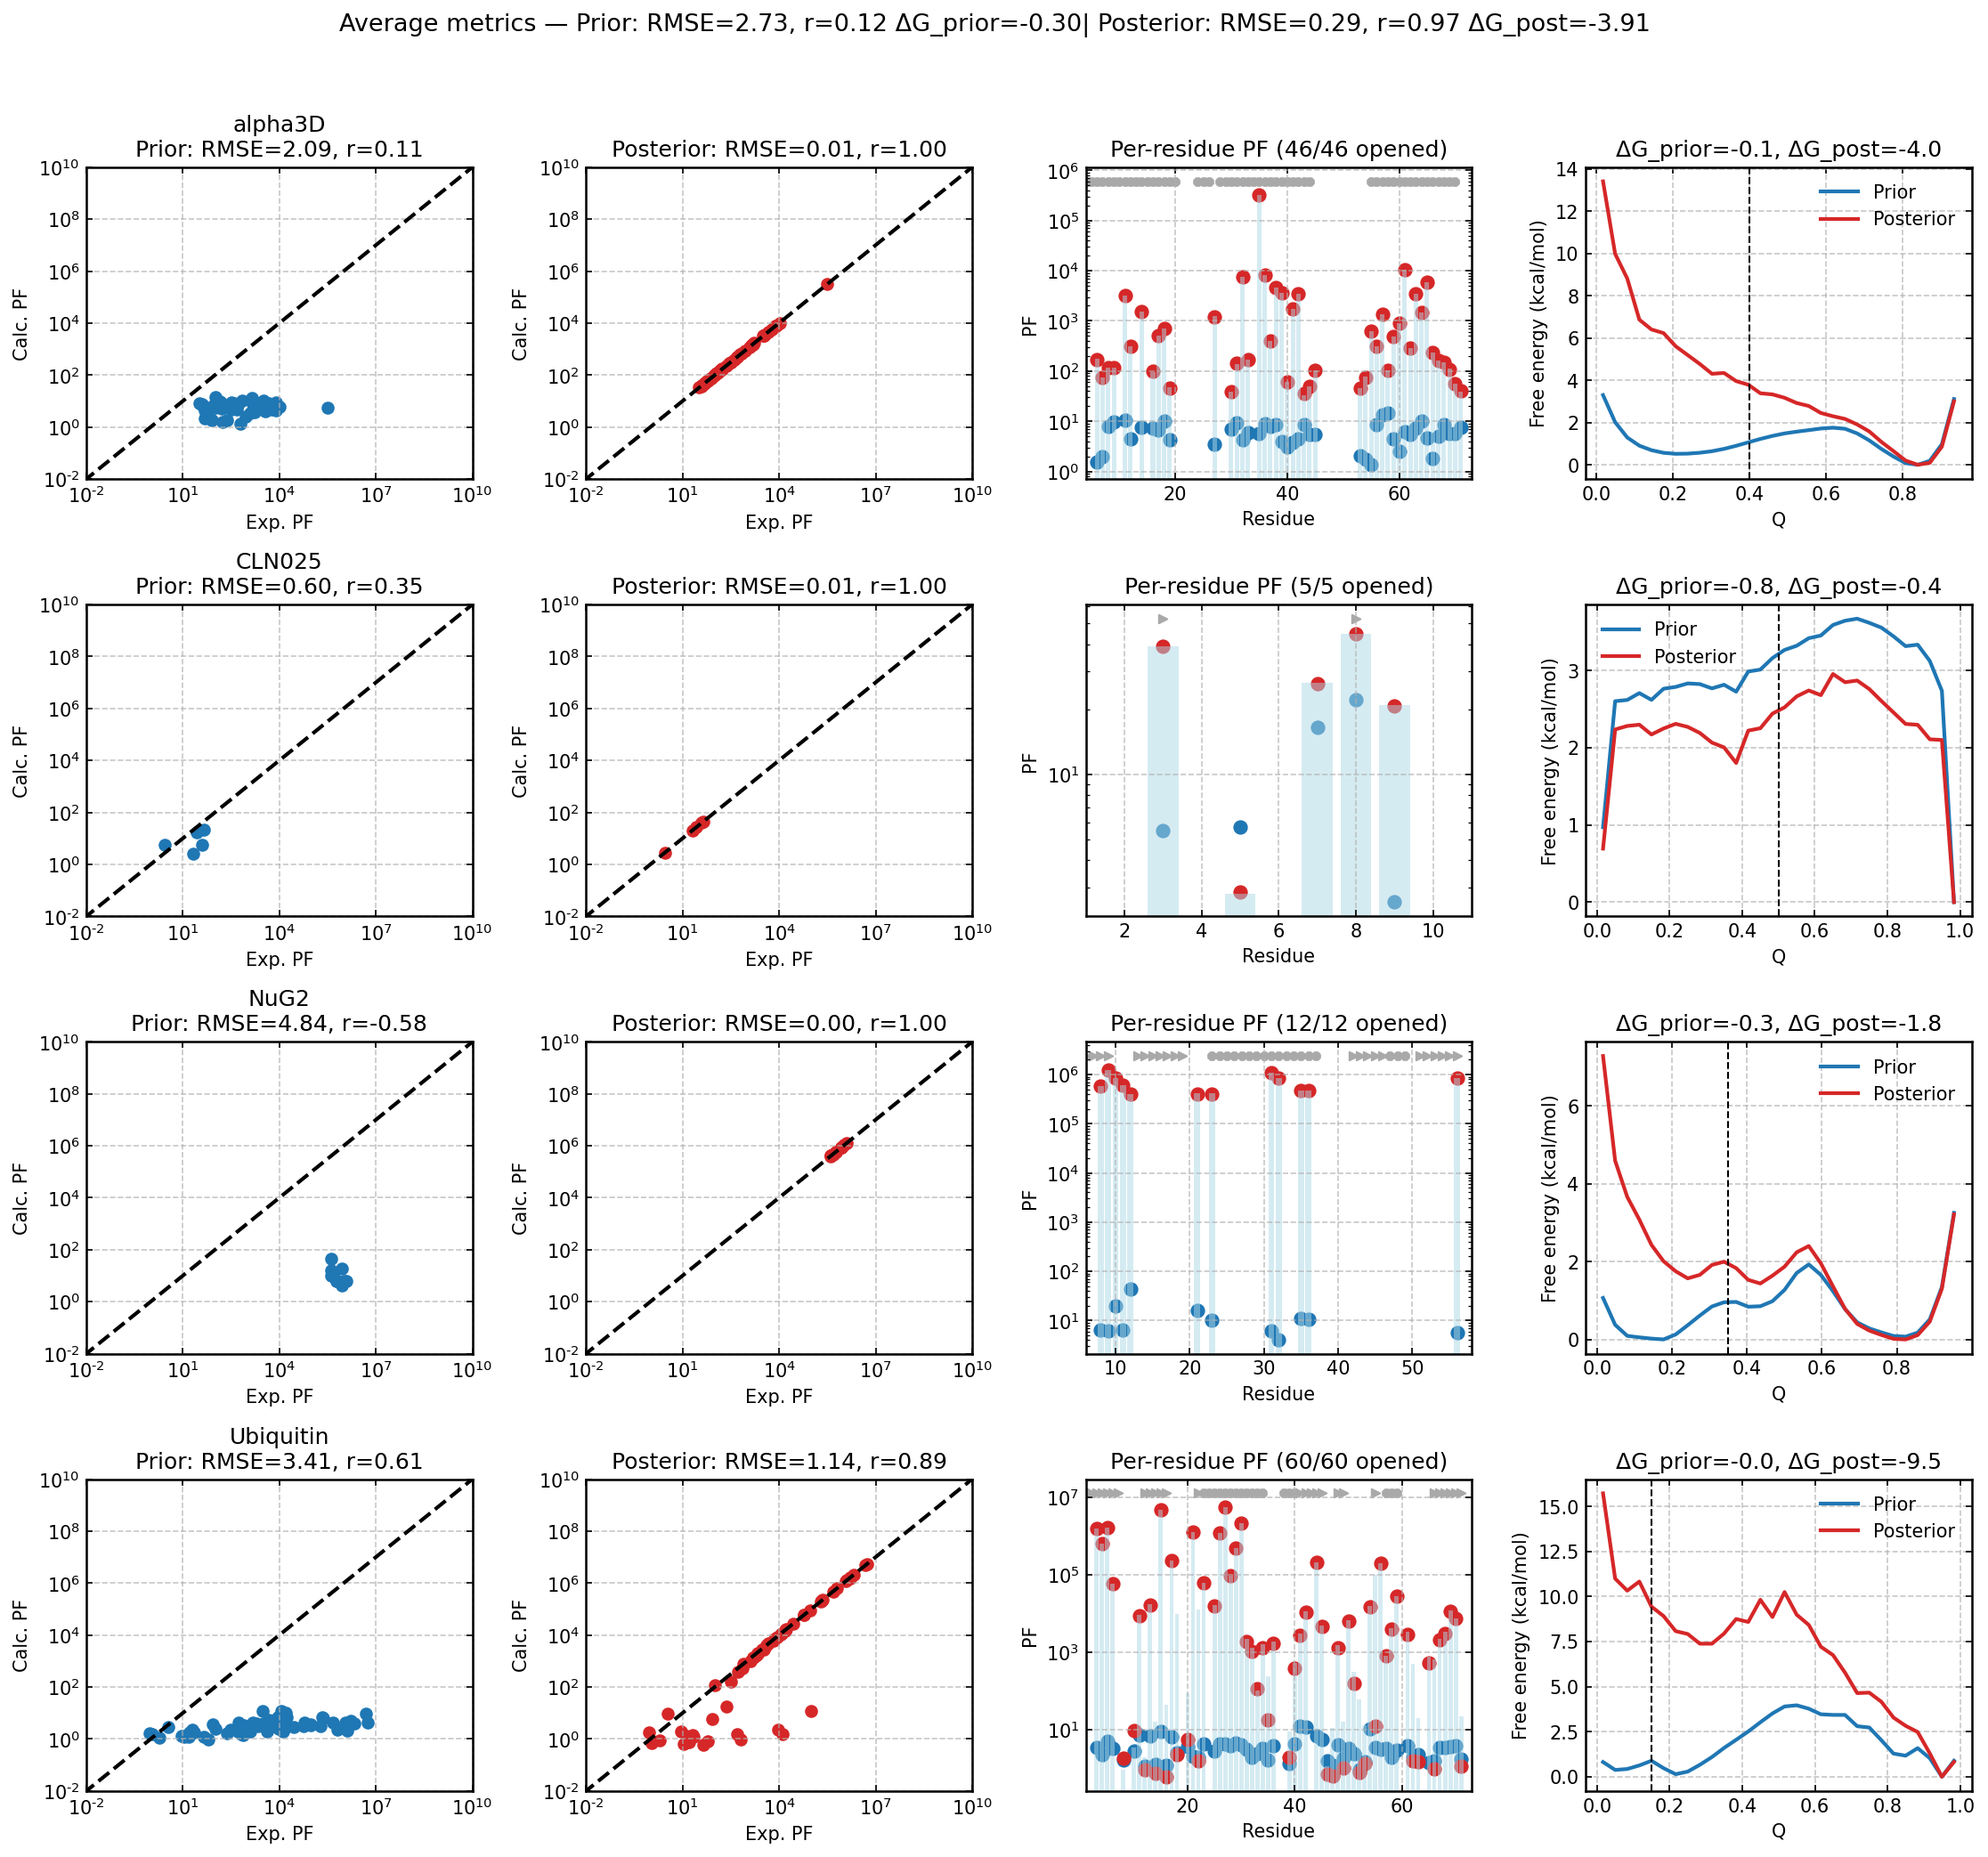

In [5]:

# --- Main plotting loop ---
model_name = 'rewM10DH_scaled'
unfolded_cutoff = 0.1
native_contacts_dir = 'native_contacts'
proteins = ['alpha3D', 'CLN025', 'NuG2', 'Ubiquitin']
Ucutoffs = [0.40,0.50,0.35,0.15]
Temps = [288,277,313,303]


n_prot = len(proteins)
fig, axes = plt.subplots(nrows=n_prot, ncols=4, figsize=(15, 3.5 * n_prot))

if n_prot == 1:
    axes = axes[np.newaxis, :]  # make 2D for s"ingle protein case

rmse_prior_all, rmse_post_all, r_prior_all, r_post_all, dG_prior_all, dG_post_all, dG_prior2_all, dG_post2_all, priorPF_all, rewPF_all, residues_all, neff_all = [], [], [], [], [], [], [], [], [], [], [], []

for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, ensemble_dir='DESRES_FOLDING_DATA', model_name=model_name)
    centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, _, _, native_cutoff, _ = compute_free_energy(protein, model_name=model_name, 
                                                    ensemble_dir='DESRES_FOLDING_DATA', native_contacts_dir = native_contacts_dir, unfolded_cutoff=Ucutoffs[i], T=Temps[i])
    
    # get dssp
    dssp = list(md.compute_dssp(md.load(f'../../DESRES_FOLDING_DATA/{protein}/exp_native_renum.pdb'), simplified =True)[0]) # native reference frame
    dssp_residues = np.arange(1, len(dssp)+1)

    expPF = np.array(exp["PF"][idxs])
    rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
    rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
    r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
    r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

    rmse_prior_all.append(rmse_prior)
    rmse_post_all.append(rmse_post)
    r_prior_all.append(r_prior)
    r_post_all.append(r_post)
    dG_prior_all.append(dG_prior)
    dG_post_all.append(dG_post)
    priorPF_all.append(priorPF)
    rewPF_all.append(rewPF)
    residues_all.append(residues)
    neff_all.append(float(stats['final neff'][0]))

    # --- Plot 1: prior vs exp ---
    ax = axes[i, 0]
    ax.scatter(expPF, priorPF, c="tab:blue", label="Prior")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")
    ax.set_title(f"{protein}\nPrior: RMSE={rmse_prior:.2f}, r={r_prior:.2f}")

    # --- Plot 2: posterior vs exp ---
    ax = axes[i, 1]
    ax.scatter(expPF, rewPF, c="tab:red", label="Posterior")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")
    ax.set_title(f"Posterior: RMSE={rmse_post:.2f}, r={r_post:.2f}")

    # --- Column 3: Per-residue PFs ---
    # Number of amides sampled open
    try:
        no_open_list = ast.literal_eval(stats['Exp residues no open state'][0])
        num_sampled_open = len(residues) - len(no_open_list)
    except: # for models like BV2006 where open state sampling is not explicitely required
        num_sampled_open = len(residues)
    ax = axes[i, 2]
    ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
    ax.scatter(residues, priorPF, color="tab:blue", linewidth=1.8, label="Prior")
    ax.scatter(residues, rewPF, color="tab:red", linewidth=1.8, label="Posterior")
    ax.set_yscale("log")
    ax.set_xlabel("Residue"); ax.set_ylabel("PF")
    ax.set_title(f"Per-residue PF ({num_sampled_open}/{len(residues)} opened)")

    # annotate with dssp
    ymin, ymax = ax.get_ylim()
    y_top = ymax + 0.02*(ymax-ymin)
    for res in range(len(dssp)):
        if dssp[res] == 'H':
            ax.scatter(dssp_residues[res], y_top, marker='8', color='darkgrey', s=20)   # triangle for helix
        elif dssp[res] == 'E':
            ax.scatter(dssp_residues[res], y_top, marker='>', color='darkgrey', s=20)  # square for sheet

    ax.set_xlim(np.min(residues)-2, np.max(residues)+2)
    #ax.legend()

    # --- Plot 4: Free energy landscape ---
    ax = axes[i, 3]
    ax.plot(centers_prior, fel_prior, color="tab:blue", label="Prior")
    ax.plot(centers_post, fel_post, color="tab:red", label="Posterior")
    ax.axvline(Ucutoffs[i], color="k", linestyle="dashed", linewidth=1.)
    ax.set_xlabel("Q"); ax.set_ylabel("Free energy (kcal/mol)")
    ax.set_title(f"ΔG_prior={dG_prior:.1f}, ΔG_post={dG_post:.1f}")
    ax.legend()

# --- save data in dictionary ---
data_dict = {}
data_dict['protein'] = proteins
data_dict['rmse prior'] = rmse_prior_all
data_dict['rmse post'] = rmse_post_all
data_dict['r prior'] = r_prior_all
data_dict['r post'] = r_post_all
data_dict['dG prior'] = dG_prior_all
data_dict['dG post'] = dG_post_all
data_dict['prior PF'] = priorPF_all
data_dict['rew PF'] = rewPF_all
data_dict['residues'] = residues_all
data_dict['neff'] = neff_all
np.save(f"{model_name}_data_dict.npy", data_dict)

# --- Supertitle with averages ---
mean_rmse_prior = np.mean(rmse_prior_all)
mean_rmse_post = np.mean(rmse_post_all)
mean_r_prior = np.mean(r_prior_all)
mean_r_post = np.mean(r_post_all)
mean_dG_prior = np.mean(dG_prior_all)
mean_dG_post = np.mean(dG_post_all)

fig.suptitle(
    f"Average metrics — Prior: RMSE={mean_rmse_prior:.2f}, r={mean_r_prior:.2f} ΔG_prior={mean_dG_prior:.2f}| "
    f"Posterior: RMSE={mean_rmse_post:.2f}, r={mean_r_post:.2f} ΔG_post={mean_dG_post:.2f}",
    fontsize=13, y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"PF_{model_name}.png", dpi=200, bbox_inches="tight")



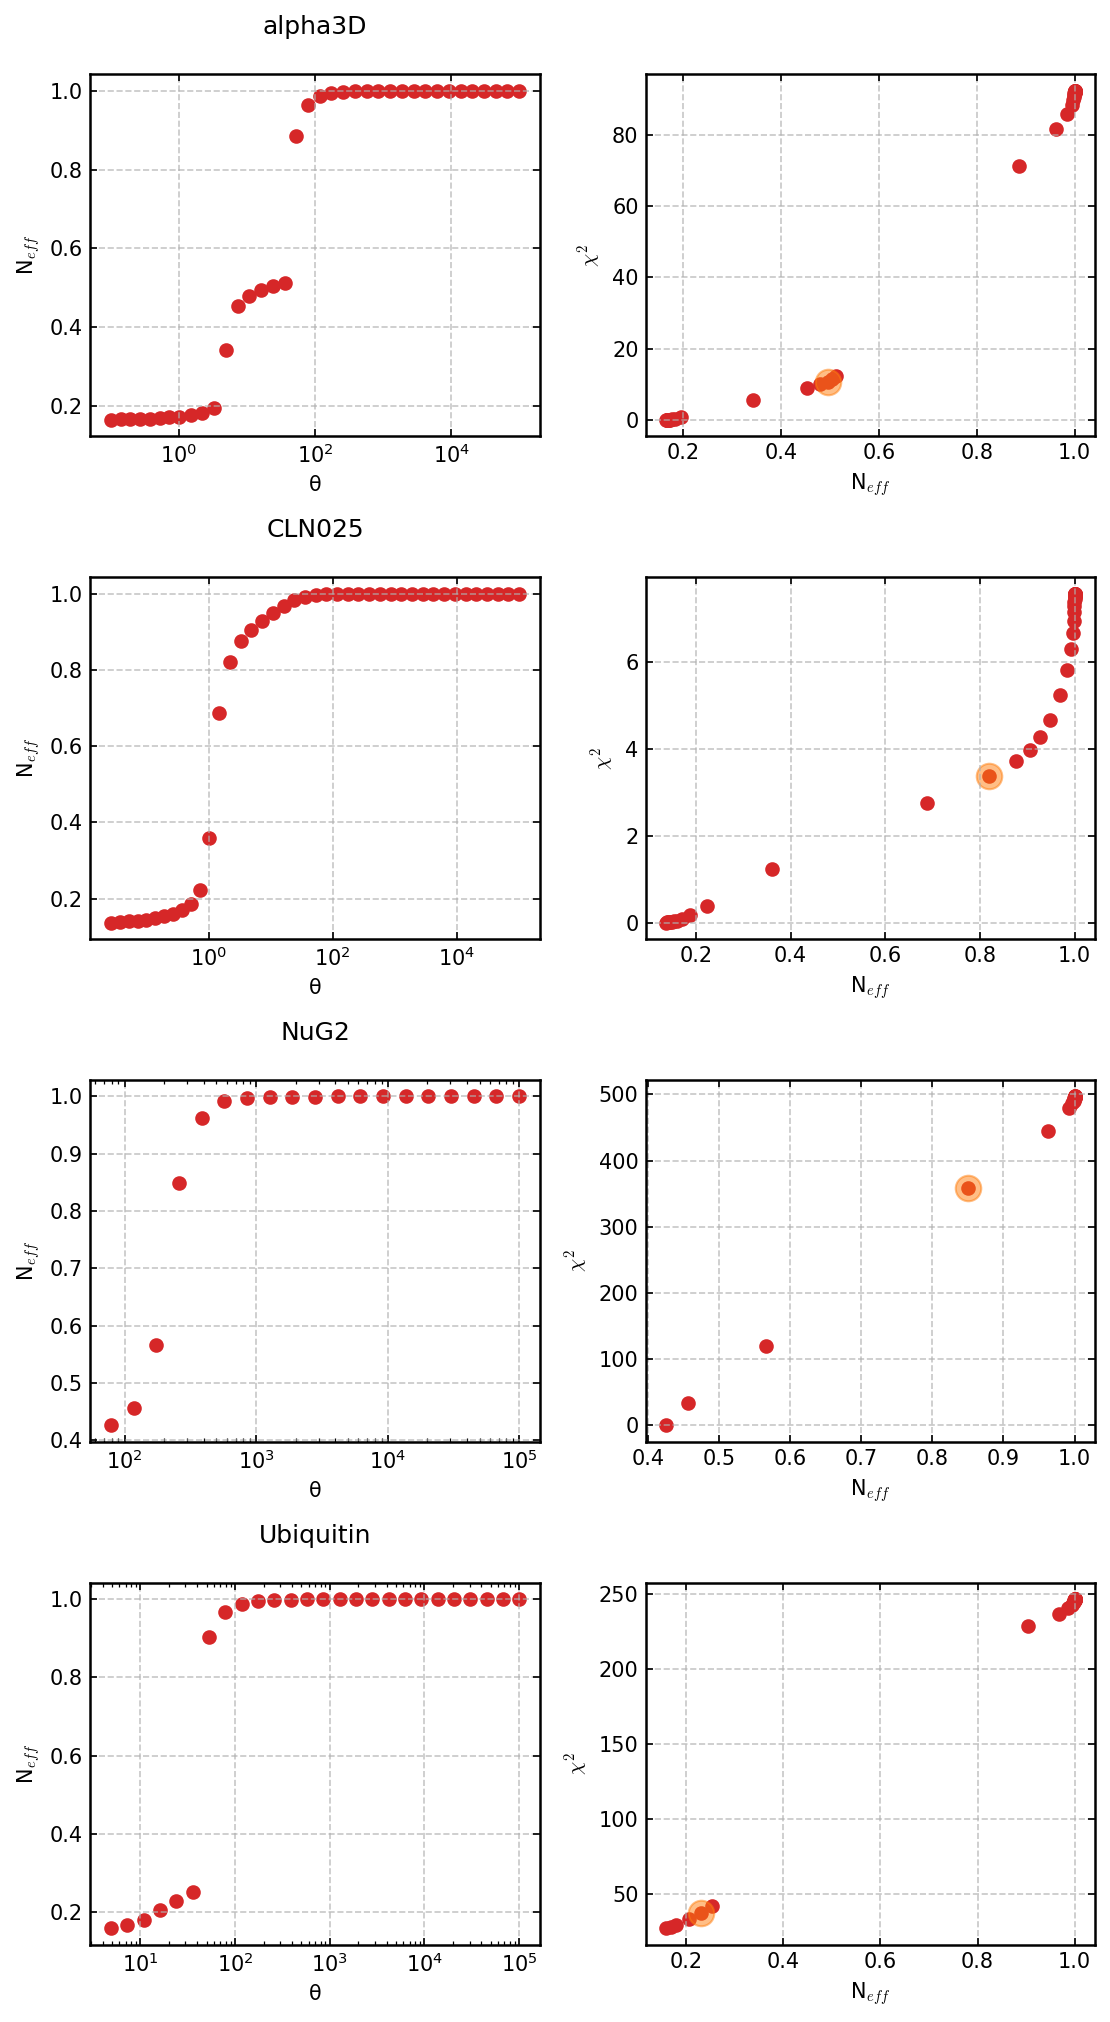

In [3]:
# reweighting curves
# phi vs theta
# chi2 vs phi

# --- Main plotting loop ---
model_name = 'rewM10DH_scaled'

native_contacts_dir = 'native_contacts'
proteins = ['alpha3D', 'CLN025', 'NuG2', 'Ubiquitin']

n_prot = len(proteins)
fig, axes = plt.subplots(nrows=n_prot, ncols=2, figsize=(7.5, 3.5 * n_prot))

if n_prot == 1:
    axes = axes[np.newaxis, :]  # make 2D for single protein case


for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model_name, ensemble_dir='DESRES_FOLDING_DATA')

    # --- Plot 1: phi vs theta ---
    ax = axes[i, 0]
    ax.scatter(thetas, phi, c="tab:red")
    ax.set_xscale("log")
    ax.set_xlabel("\u03B8"); ax.set_ylabel("N$_{eff}$")
    ax.set_title(f"{protein}\n")

    # --- Plot 2: RMSE vs Neff ---
    el_idx, el_x, el_y = find_elbow(phi, chi2)
    el_idx +=1
    ax = axes[i, 1]
    ax.scatter(phi, chi2, c="tab:red")
    ax.scatter(phi[el_idx], chi2[el_idx], s=150, c='tab:orange', alpha=0.5)
    
    ax.set_ylabel(r"$\chi^{2}$"); ax.set_xlabel("N$_{eff}$")

    
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"rewcurves_{model_name}_elbow.png", dpi=200, bbox_inches="tight")


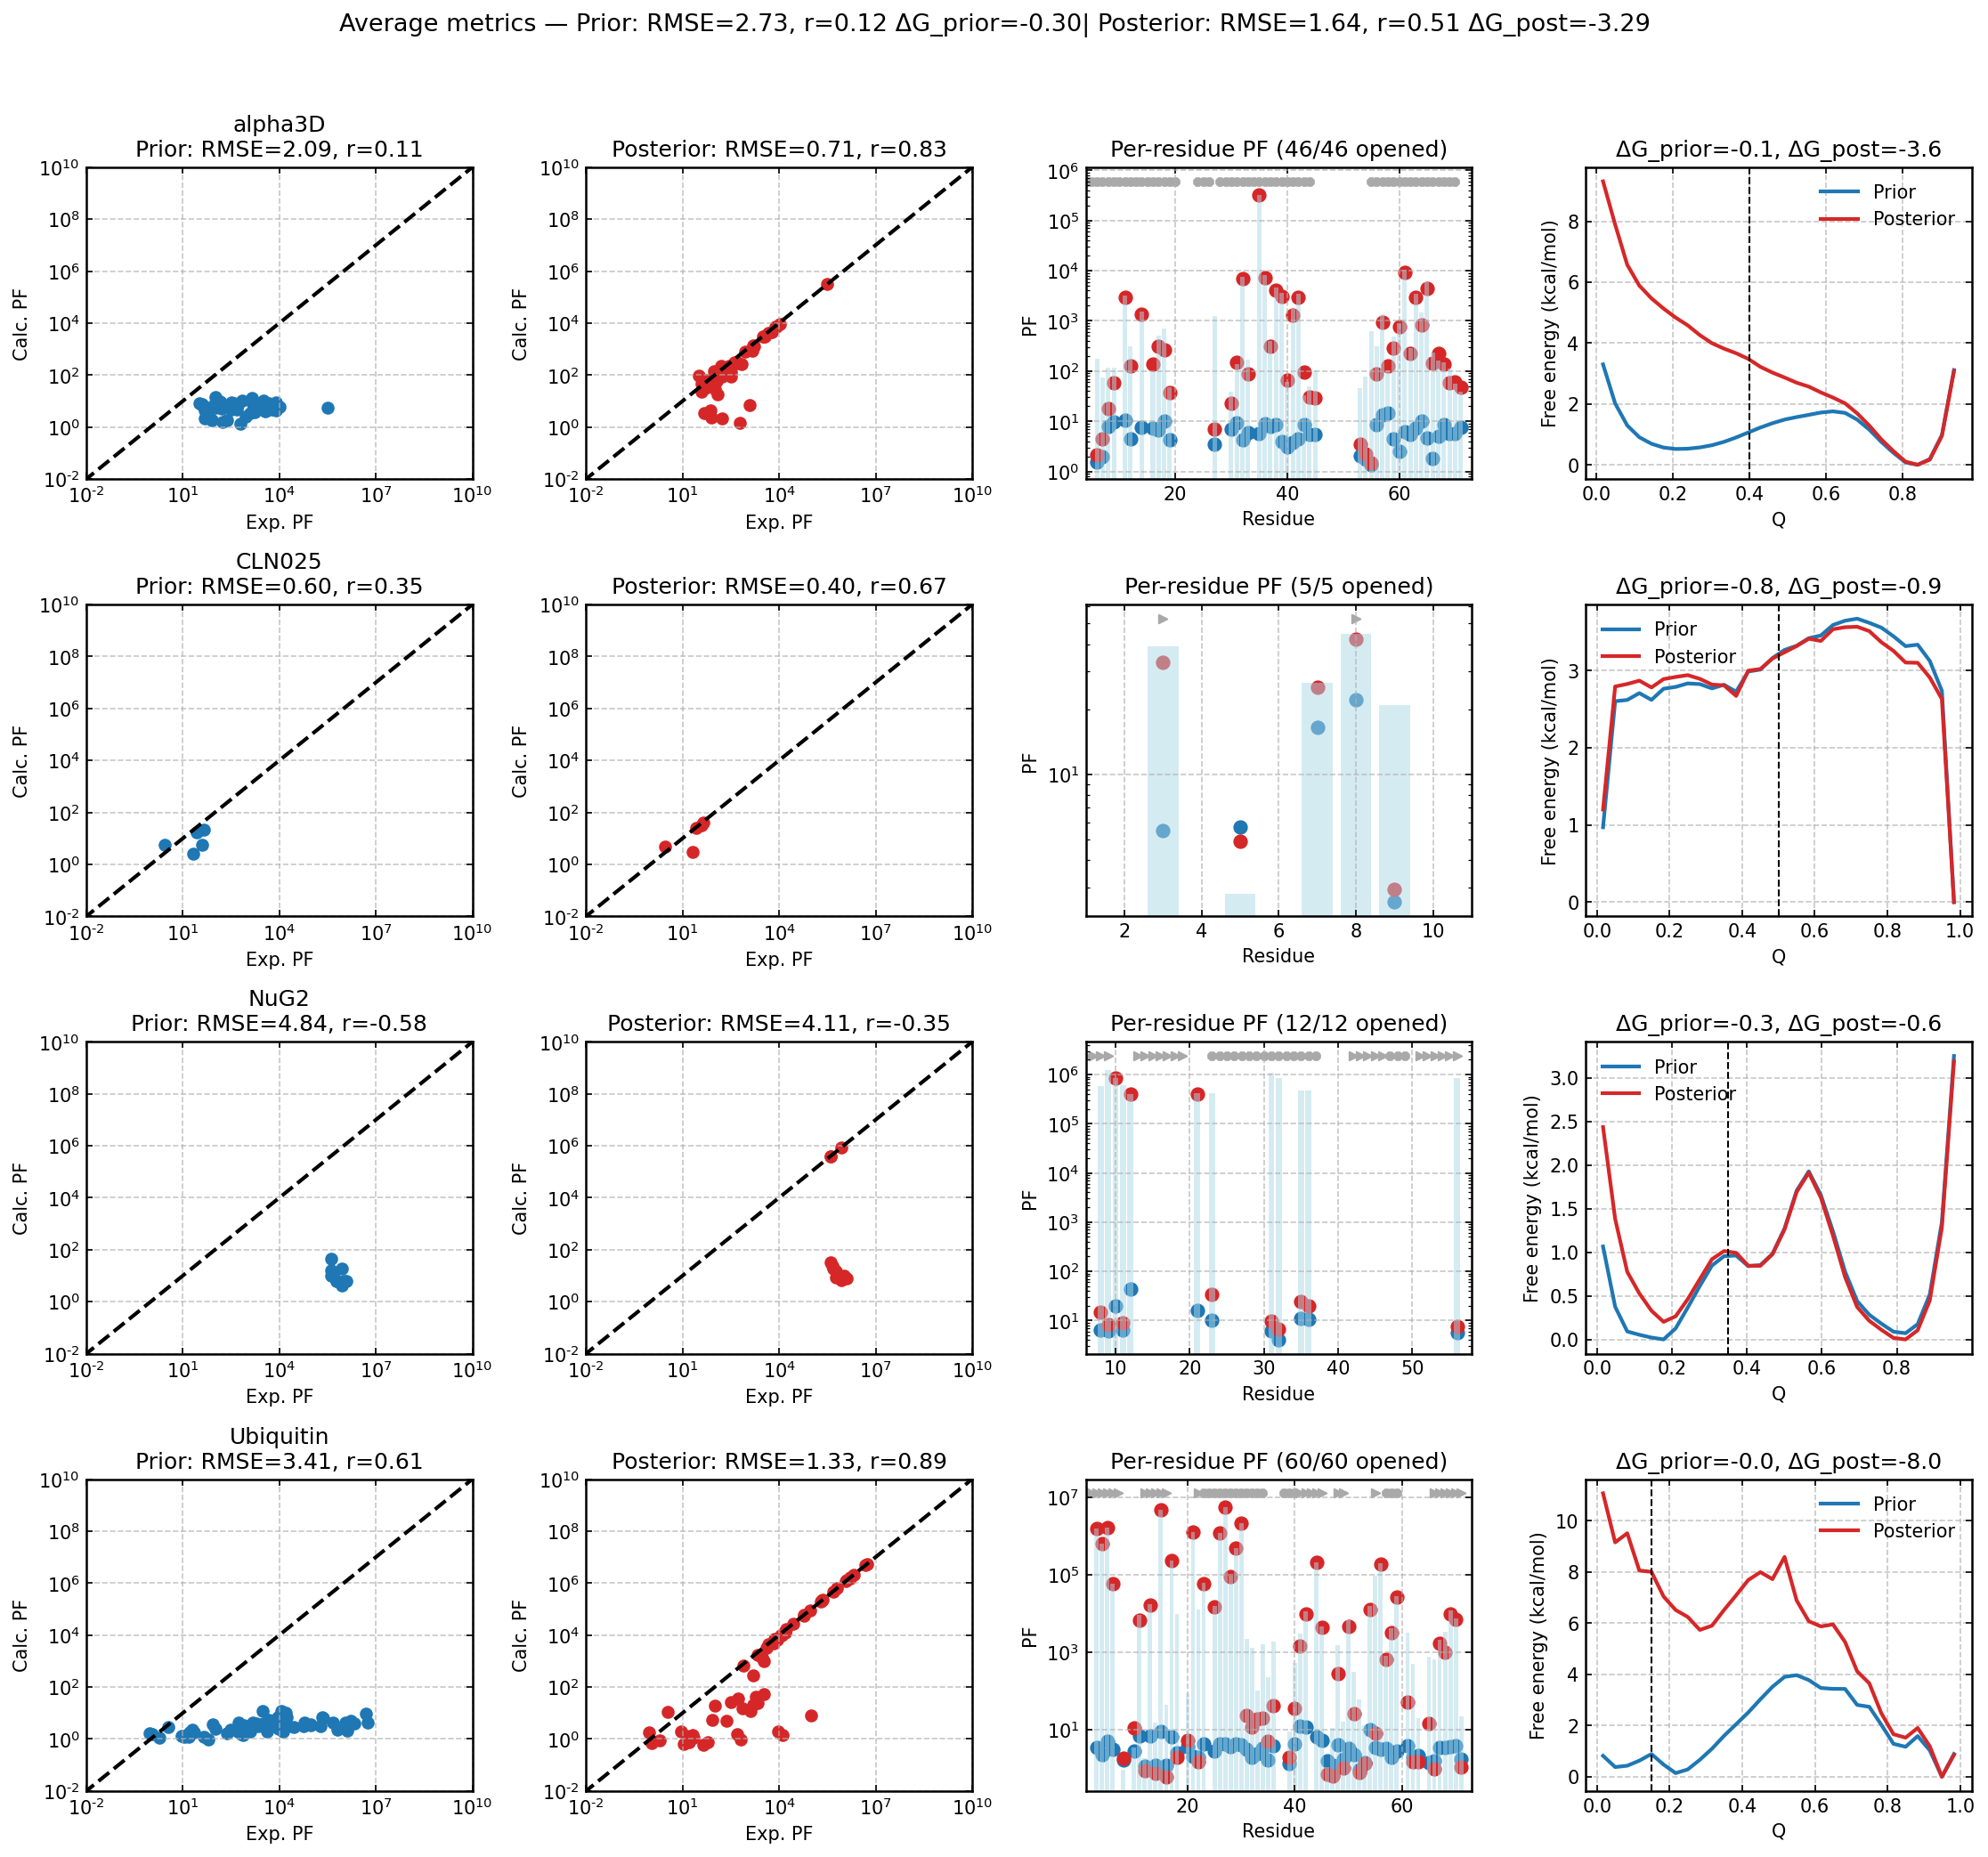

In [6]:
# --- Main plotting loop ---
model_name = 'rewM10DH_scaled'
unfolded_cutoff = 0.1
native_contacts_dir = 'native_contacts'
proteins = ['alpha3D', 'CLN025', 'NuG2', 'Ubiquitin']
Ucutoffs = [0.40,0.50,0.35,0.15]
Temps = [288,277,313,303]


n_prot = len(proteins)
fig, axes = plt.subplots(nrows=n_prot, ncols=4, figsize=(15, 3.5 * n_prot))

if n_prot == 1:
    axes = axes[np.newaxis, :]  # make 2D for s"ingle protein case

rmse_prior_all, rmse_post_all, r_prior_all, r_post_all, dG_prior_all, dG_post_all, priorPF_all, rewPF_all, residues_all, neff_all = [], [], [], [], [], [], [], [], [], []

for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, ensemble_dir='DESRES_FOLDING_DATA', model_name=model_name)
    
    
    el_idx, el_x, el_y = find_elbow(phi, chi2)
    el_idx +=1
    # elbow weights
    wopt = np.load(f"../../DESRES_FOLDING_DATA/{protein}/{model_name}/log_lambda_wopt_elbow.npy")
    # recalculate posterior
    all_residues = np.loadtxt(f"../../DESRES_FOLDING_DATA/{protein}/{model_name}/amideresidues.txt")
    res_idxs = np.array([list(all_residues).index(ele) for ele in residues])
    O_files = ['fopen.npy', 'fopenDH.npy', 'O.npy']
    for ofile in O_files:
        if os.path.exists(f"../../DESRES_FOLDING_DATA/{protein}/{model_name}/{ofile}"):
            O = np.load(f"../../DESRES_FOLDING_DATA/{protein}/{model_name}/{ofile}")
            break
    PF = 1/np.average(O, axis=0, weights=wopt)
    rewPF = PF[res_idxs]

    centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, _, _, native_cutoff, _ = compute_free_energy(protein, model_name=model_name, 
                                                    ensemble_dir='DESRES_FOLDING_DATA', native_contacts_dir = native_contacts_dir, unfolded_cutoff=Ucutoffs[i], wopt=wopt, T=Temps[i])
    
    # get dssp
    dssp = list(md.compute_dssp(md.load(f'../../DESRES_FOLDING_DATA/{protein}/exp_native_renum.pdb'), simplified =True)[0]) # native reference frame
    dssp_residues = np.arange(1, len(dssp)+1)

    expPF = np.array(exp["PF"][idxs])
    rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
    rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
    r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
    r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

    rmse_prior_all.append(rmse_prior)
    rmse_post_all.append(rmse_post)
    r_prior_all.append(r_prior)
    r_post_all.append(r_post)
    dG_prior_all.append(dG_prior)
    dG_post_all.append(dG_post)
    priorPF_all.append(priorPF)
    rewPF_all.append(rewPF)
    residues_all.append(residues)
    neff_all.append(phi[el_idx])

    # --- Plot 1: prior vs exp ---
    ax = axes[i, 0]
    ax.scatter(expPF, priorPF, c="tab:blue", label="Prior")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")
    ax.set_title(f"{protein}\nPrior: RMSE={rmse_prior:.2f}, r={r_prior:.2f}")

    # --- Plot 2: posterior vs exp ---
    ax = axes[i, 1]
    ax.scatter(expPF, rewPF, c="tab:red", label="Posterior")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")
    ax.set_title(f"Posterior: RMSE={rmse_post:.2f}, r={r_post:.2f}")

    # --- Column 3: Per-residue PFs ---
    # Number of amides sampled open
    try:
        no_open_list = ast.literal_eval(stats['Exp residues no open state'][0])
        num_sampled_open = len(residues) - len(no_open_list)
    except: # for models like BV2006 where open state sampling is not explicitely required
        num_sampled_open = len(residues)
    ax = axes[i, 2]
    ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
    ax.scatter(residues, priorPF, color="tab:blue", linewidth=1.8, label="Prior")
    ax.scatter(residues, rewPF, color="tab:red", linewidth=1.8, label="Posterior")
    ax.set_yscale("log")
    ax.set_xlabel("Residue"); ax.set_ylabel("PF")
    ax.set_title(f"Per-residue PF ({num_sampled_open}/{len(residues)} opened)")

    # annotate with dssp
    ymin, ymax = ax.get_ylim()
    y_top = ymax + 0.02*(ymax-ymin)
    for res in range(len(dssp)):
        if dssp[res] == 'H':
            ax.scatter(dssp_residues[res], y_top, marker='8', color='darkgrey', s=20)   # triangle for helix
        elif dssp[res] == 'E':
            ax.scatter(dssp_residues[res], y_top, marker='>', color='darkgrey', s=20)  # square for sheet

    ax.set_xlim(np.min(residues)-2, np.max(residues)+2)
    #ax.legend()

    # --- Plot 4: Free energy landscape ---
    ax = axes[i, 3]
    ax.plot(centers_prior, fel_prior, color="tab:blue", label="Prior")
    ax.plot(centers_post, fel_post, color="tab:red", label="Posterior")
    ax.axvline(Ucutoffs[i], color="k", linestyle="dashed", linewidth=1.)
    ax.set_xlabel("Q"); ax.set_ylabel("Free energy (kcal/mol)")
    ax.set_title(f"ΔG_prior={dG_prior:.1f}, ΔG_post={dG_post:.1f}")
    ax.legend()

# --- save data in dictionary ---
data_dict = {}
data_dict['protein'] = proteins
data_dict['rmse prior'] = rmse_prior_all
data_dict['rmse post'] = rmse_post_all
data_dict['r prior'] = r_prior_all
data_dict['r post'] = r_post_all
data_dict['dG prior'] = dG_prior_all
data_dict['dG post'] = dG_post_all
data_dict['prior PF'] = priorPF_all
data_dict['rew PF'] = rewPF_all
data_dict['residues'] = residues_all
data_dict['neff'] = neff_all
np.save(f"{model_name}_data_dict_elbow_posterior.npy", data_dict)

# --- Supertitle with averages ---
mean_rmse_prior = np.mean(rmse_prior_all)
mean_rmse_post = np.mean(rmse_post_all)
mean_r_prior = np.mean(r_prior_all)
mean_r_post = np.mean(r_post_all)
mean_dG_prior = np.mean(dG_prior_all)
mean_dG_post = np.mean(dG_post_all)

fig.suptitle(
    f"Average metrics — Prior: RMSE={mean_rmse_prior:.2f}, r={mean_r_prior:.2f} ΔG_prior={mean_dG_prior:.2f}| "
    f"Posterior: RMSE={mean_rmse_post:.2f}, r={mean_r_post:.2f} ΔG_post={mean_dG_post:.2f}",
    fontsize=13, y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"PF_{model_name}_elbow_posterior.png", dpi=200, bbox_inches="tight")

